# OmniBand: AI/ML analytics for student wellness

**Krutpunya · 24E4034 · Electronics & Instrumentation Engineering, IET DAVV, Indore**

This notebook is the AI/ML part of the OmniBand project. The band sends heart rate, SpO₂, activity, sitting time, posture, breaks, steps and skin temperature to ThingSpeak. The website shows them live. This notebook answers a different question:

> *What kinds of study-and-health habits exist among students, which kind is each student closest to, and what should each one do about it?*

**What it does**

1. Builds a **simulated cohort of 300 students** (a real cohort needs consent and ethics approval, which a course project does not have).
2. Groups students with **K-Means clustering** and checks the groups with the silhouette score.
3. Shows the groups with **PCA**.
4. Runs an **Isolation Forest** anomaly detector on a single student's time series and measures how well it finds *injected* anomalies.
5. Pulls **your own data from ThingSpeak**, assigns it to a cluster and writes **plain-language recommendations**.
6. Exports the cohort averages used by the website's "You vs cohort" chart.

> **Honest limits.** The cohort is simulated, so the clusters show that the *method* works, not that real students behave this way. Stress, posture, anomaly and temperature are experimental estimates from low-cost sensors. Nothing here is a medical diagnosis.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RNG = np.random.default_rng(42)          # fixed seed: same results every run
TEAL, CORAL, AMBER, INK = "#0f9d8a", "#ee5b5b", "#e8a317", "#0f2230"
print("Ready")

Ready


## 1. Simulated cohort (clearly labelled as simulated)

Each student is one row of **daily summary features**, the same quantities the band measures. Three habit patterns are used to generate the data. The pattern a student was generated from is stored in `true_group` **only so we can check the clustering afterwards**. The model never sees it.

In [2]:
FEATURES = ["avg_hr", "avg_spo2", "avg_activity", "max_sit_min", "breaks_per_hr",
            "steps_day", "avg_posture", "avg_stress", "avg_temp", "avg_anomaly"]

# mean and standard deviation for each pattern, in the order of FEATURES
PATTERNS = {
    "Balanced":  (0.40, [72, 97.5, 3.5, 38, 1.4, 8000, 82, 20, 34.0, 12], [5, 0.8, 0.8,  8, 0.3, 1500, 6,  8, 0.4,  6]),
    "Sedentary": (0.35, [78, 97.2, 1.3, 72, 0.4, 3200, 62, 35, 34.1, 18], [5, 0.9, 0.5, 12, 0.2,  900, 8, 10, 0.4,  8]),
    "Stressed":  (0.25, [92, 97.0, 2.0, 55, 0.8, 5000, 70, 68, 34.4, 40], [6, 1.0, 0.7, 10, 0.3, 1200, 8, 10, 0.4, 12]),
}
N = 300
rows, labels = [], []
for name, (share, mu, sd) in PATTERNS.items():
    n = int(round(N * share))
    rows.append(RNG.normal(mu, sd, size=(n, len(FEATURES))))
    labels += [name] * n
cohort = pd.DataFrame(np.vstack(rows), columns=FEATURES)
cohort["true_group"] = labels

# keep values physically sensible
cohort["avg_spo2"] = cohort["avg_spo2"].clip(92, 100)
cohort["avg_posture"] = cohort["avg_posture"].clip(20, 100)
cohort["avg_stress"] = cohort["avg_stress"].clip(0, 100)
cohort["avg_anomaly"] = cohort["avg_anomaly"].clip(0, 100)
for c in ["avg_activity", "max_sit_min", "breaks_per_hr", "steps_day"]:
    cohort[c] = cohort[c].clip(lower=0)
cohort = cohort.sample(frac=1, random_state=1).reset_index(drop=True)
cohort.insert(0, "student_id", [f"S{i+1:03d}" for i in range(len(cohort))])
cohort.round(2).head()

,student_id,avg_hr,avg_spo2,avg_activity,max_sit_min,breaks_per_hr,steps_day,avg_posture,avg_stress,avg_temp,avg_anomaly,true_group
0,S001,83.12,96.50,0.73,46.13,0.35,2676.57,49.59,39.53,33.92,9.39,Sedentary
1,S002,75.25,96.19,0.71,73.04,0.47,2486.73,62.21,40.71,34.35,30.42,Sedentary
2,S003,74.79,97.41,1.15,80.07,0.50,2577.26,60.65,45.44,34.26,6.82,Sedentary
3,S004,78.49,99.30,1.11,75.89,0.24,2883.63,63.99,43.46,34.23,28.07,Sedentary
4,S005,71.23,98.66,3.13,47.06,1.21,7909.62,75.57,23.64,34.58,11.54,Balanced


In [3]:
cohort[FEATURES].describe().round(1)

,avg_hr,avg_spo2,avg_activity,max_sit_min,breaks_per_hr,steps_day,avg_posture,avg_stress,avg_temp,avg_anomaly
count,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0
mean,78.5,97.3,2.3,53.2,0.9,5511.9,72.3,37.7,34.2,21.6
std,9.1,0.9,1.2,18.0,0.5,2485.5,11.9,21.6,0.5,15.0
min,60.0,94.6,0.1,17.5,0.0,457.1,43.2,0.0,33.0,0.0
25%,71.9,96.7,1.4,38.8,0.4,3465.7,63.2,21.3,33.8,11.1
50%,77.0,97.4,2.2,50.6,0.8,5110.4,73.7,31.9,34.1,17.0
75%,83.9,97.9,3.2,66.7,1.3,7559.0,82.0,51.3,34.4,28.2
max,105.6,99.5,5.2,106.3,2.0,11491.5,100.0,91.3,35.4,69.9


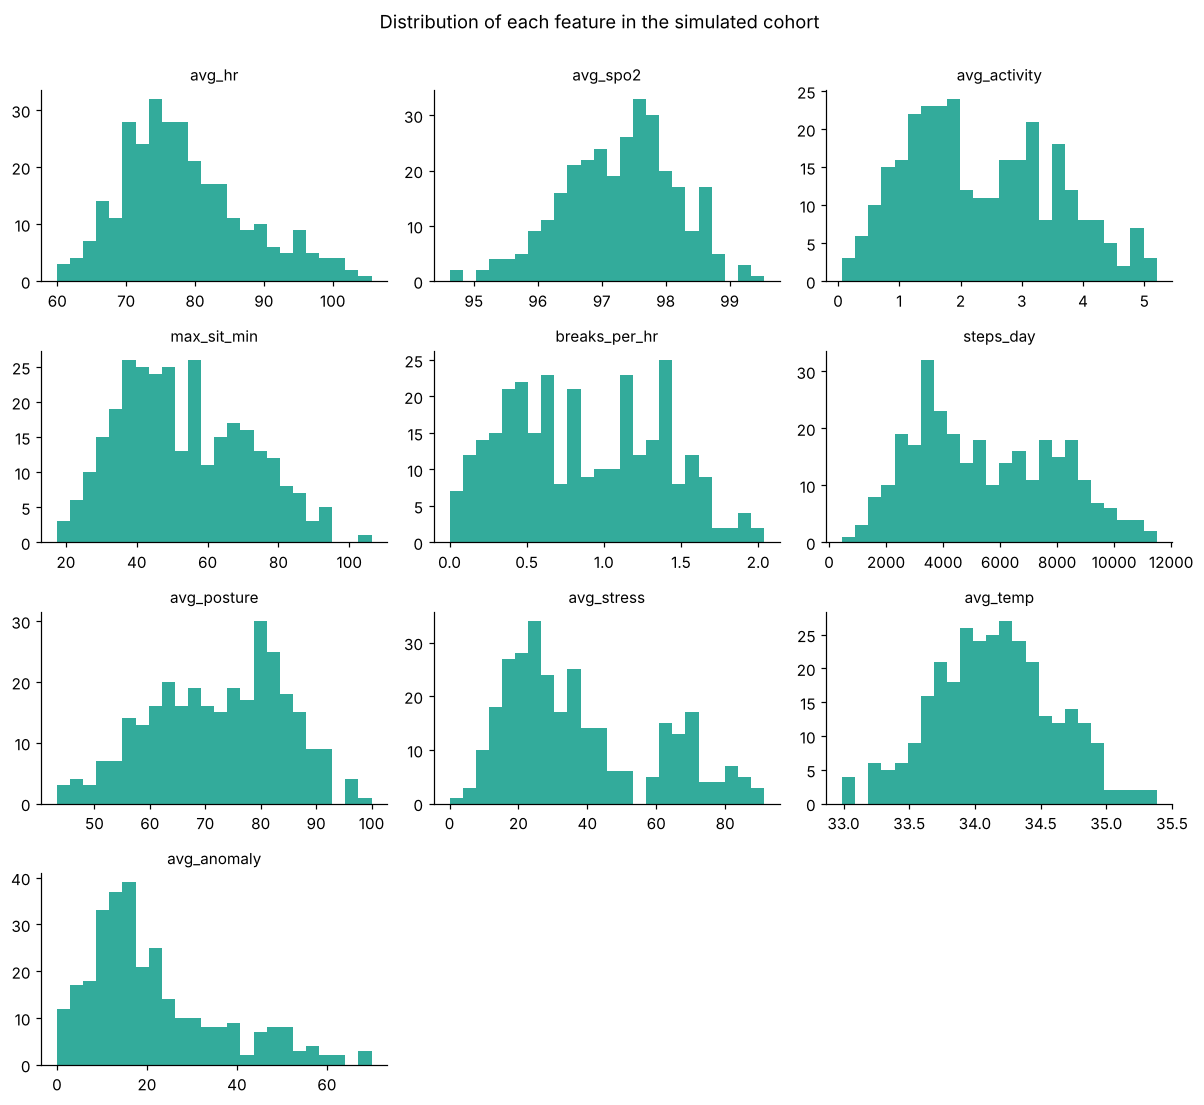

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(11, 10))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(cohort[f], bins=24, color=TEAL, alpha=.85)
    ax.set_title(f, fontsize=10)
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Distribution of each feature in the simulated cohort", y=1.0)
plt.tight_layout(); plt.show()

## 2. Choosing the number of clusters

Features are on very different scales (steps in thousands, SpO₂ near 97), so they are **standardised** first. We try k = 2 to 7 and look at two checks: inertia (the "elbow") and the **silhouette score** (closer to 1 means cleaner, better separated groups).

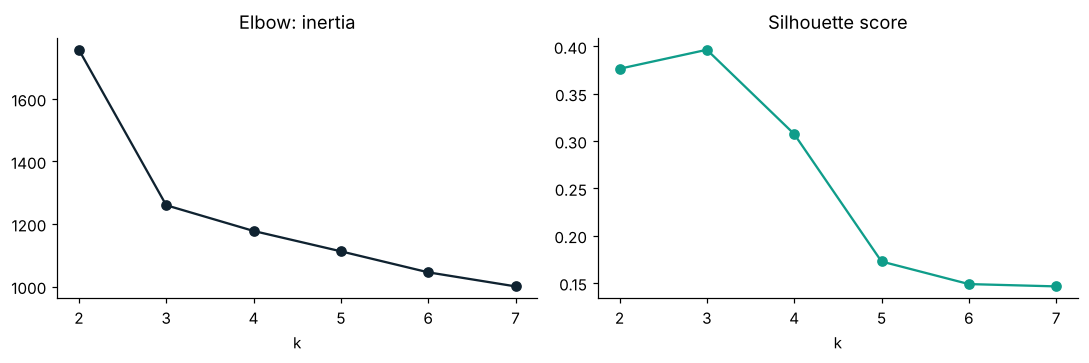

{2: 0.376, 3: 0.396, 4: 0.307, 5: 0.173, 6: 0.149, 7: 0.146}


In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(cohort[FEATURES])

ks = range(2, 8)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(ks), inertia, "o-", color=INK); ax[0].set_title("Elbow: inertia"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-", color=TEAL);   ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sil)})

The silhouette score is highest at k = 3 (about 0.40) and drops sharply for larger k, and the elbow bends near 3 as well. Three groups also translate into three clear pieces of advice for a student (long-sitter, high-stress, balanced). A score of about 0.4 is moderate, meaning the groups overlap a little, which is normal for human habits. (Because the data was simulated from three patterns, k = 3 is expected here. That is the method working, not a discovery about real students.)

## 3. K-Means clustering and PCA view

Variance explained by the 2 plot axes: [0.45 0.2 ] = 0.65


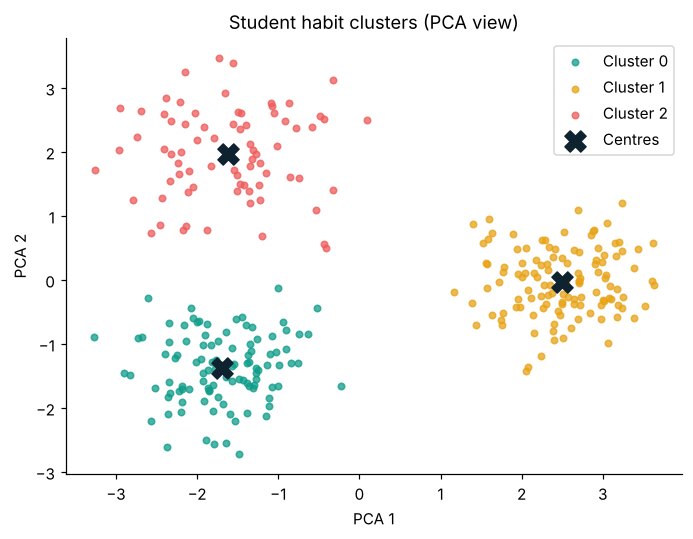

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
cohort["cluster"] = km.labels_

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print("Variance explained by the 2 plot axes:", np.round(pca.explained_variance_ratio_, 2), "=", round(pca.explained_variance_ratio_.sum(), 2))

fig, ax = plt.subplots(figsize=(6.4, 5))
colors = [TEAL, AMBER, CORAL]
for c in range(3):
    m = cohort["cluster"] == c
    ax.scatter(Z[m, 0], Z[m, 1], s=18, alpha=.75, color=colors[c], label=f"Cluster {c}")
cz = pca.transform(km.cluster_centers_)
ax.scatter(cz[:, 0], cz[:, 1], marker="X", s=190, color=INK, label="Centres")
ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2"); ax.set_title("Student habit clusters (PCA view)")
ax.legend(); plt.tight_layout(); plt.show()

### Naming the clusters from their profile

In [7]:
profile = cohort.groupby("cluster")[FEATURES].mean()

# name each cluster from its own averages, never by hand
sit_c    = profile["max_sit_min"].idxmax()
stress_c = profile["avg_stress"].idxmax() if profile["avg_stress"].idxmax() != sit_c else profile["avg_stress"].drop(sit_c).idxmax()
names = {c: "Balanced mover" for c in profile.index}
names[sit_c] = "Long-sitter"
names[stress_c] = "High-stress"
cohort["group"] = cohort["cluster"].map(names)

summary = cohort.groupby("group")[FEATURES].mean().round(1)
summary["students"] = cohort["group"].value_counts()
summary

,avg_hr,avg_spo2,avg_activity,max_sit_min,breaks_per_hr,steps_day,avg_posture,avg_stress,avg_temp,avg_anomaly,students
group,,,,,,,,,,,
Balanced mover,71.9,97.5,3.5,37.4,1.3,8011.7,82.3,20.6,34.0,11.5,120
High-stress,90.8,97.2,2.0,53.4,0.8,4865.5,71.1,69.9,34.5,42.1,75
Long-sitter,77.4,97.1,1.2,71.0,0.4,3116.8,61.8,34.2,34.1,18.4,105


In [8]:
# How well did the clusters recover the patterns the data was generated from?
ari = adjusted_rand_score(cohort["true_group"], cohort["cluster"])
print(f"Adjusted Rand Index vs generating pattern: {ari:.2f}   (1.0 = perfect, 0 = random)")
print(f"Silhouette score at k=3: {silhouette_score(X, km.labels_):.2f}")
pd.crosstab(cohort["true_group"], cohort["group"])

Adjusted Rand Index vs generating pattern: 1.00   (1.0 = perfect, 0 = random)
Silhouette score at k=3: 0.40


group,Balanced mover,High-stress,Long-sitter
true_group,,,
Balanced,120,0,0
Sedentary,0,0,105
Stressed,0,75,0


**Reading this:** the table shows how many students from each generating pattern landed in each cluster. This check only makes sense because we know the answer for simulated data. With a real cohort there is no `true_group`, and you would judge clusters by silhouette score and by whether the profiles make sense.

## 4. Anomaly detection on one student's time series (Isolation Forest)

The band sends a reading every ~20 seconds. Here we simulate **6 hours of one student's day at 1-minute resolution**, inject a few known events (a sustained racing heart rate at rest, and a dip in SpO₂), and see whether an **Isolation Forest** flags them. Because we injected the events, we can measure precision and recall honestly.

This is the kind of logic behind the dashboard's *anomaly score*. The website itself uses a simpler rule-based version that runs in the browser.

Injected anomaly minutes: 33   flagged: 29
Precision 0.97   Recall 0.85


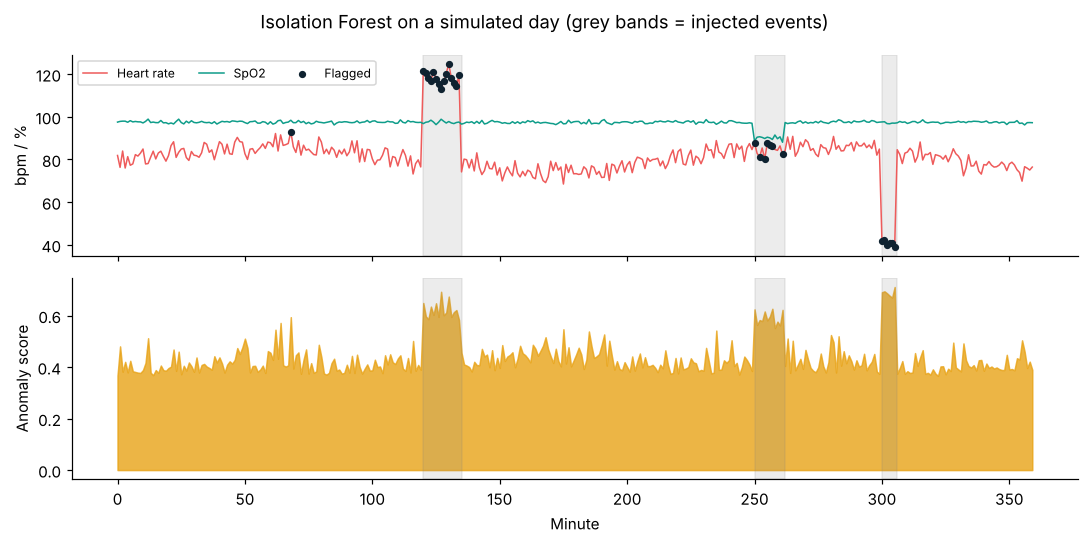

In [9]:
T = 360
t = np.arange(T)
act = np.clip(2.5 + 1.5*np.sin(t/35) + RNG.normal(0, .4, T), 0, None)
hr  = 70 + 4*act + RNG.normal(0, 2.2, T)
spo = 97.5 + RNG.normal(0, .5, T)
truth = np.zeros(T, dtype=bool)

# injected events
hr[120:135] = 118 + RNG.normal(0, 3, 15); act[120:135] = 0.4; truth[120:135] = True    # racing heart at rest
spo[250:262] = 90 + RNG.normal(0, .8, 12);                    truth[250:262] = True    # low SpO2
hr[300:306] = 40 + RNG.normal(0, 1.5, 6);  act[300:306] = 0.3; truth[300:306] = True    # very slow pulse

ts = pd.DataFrame({"hr": hr, "spo2": spo, "activity": act})
ts["hr_vs_expected"] = ts["hr"] - (70 + 4*ts["activity"])      # how far HR is from what movement explains
feat = ts[["hr", "spo2", "activity", "hr_vs_expected"]]

iso = IsolationForest(contamination=0.08, random_state=42).fit(StandardScaler().fit_transform(feat))
pred = iso.predict(StandardScaler().fit_transform(feat)) == -1
score = -iso.score_samples(StandardScaler().fit_transform(feat))   # higher = more unusual

tp = int((pred & truth).sum()); fp = int((pred & ~truth).sum()); fn = int((~pred & truth).sum())
prec, rec = tp / max(1, tp + fp), tp / max(1, tp + fn)
print(f"Injected anomaly minutes: {truth.sum()}   flagged: {pred.sum()}")
print(f"Precision {prec:.2f}   Recall {rec:.2f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, hr, color=CORAL, lw=1, label="Heart rate"); ax[0].plot(t, spo, color=TEAL, lw=1, label="SpO2")
ax[0].scatter(t[pred], hr[pred], s=14, color=INK, zorder=3, label="Flagged"); ax[0].legend(ncol=3, fontsize=8)
ax[0].set_ylabel("bpm / %")
ax[1].fill_between(t, score, color=AMBER, alpha=.8); ax[1].set_ylabel("Anomaly score"); ax[1].set_xlabel("Minute")
for a in ax:
    for s, e in [(120, 135), (250, 262), (300, 306)]:
        a.axvspan(s, e, color="grey", alpha=.15)
fig.suptitle("Isolation Forest on a simulated day (grey bands = injected events)")
plt.tight_layout(); plt.show()

This shows the *method* works when anomalies are clear. A real wrist PPG sensor (MAX30100) is noisy, especially when the hand moves, so real use needs a personal baseline, motion filtering and clinical validation. That is the main future-work item.

## 5. Your own data from ThingSpeak

This reads your public channel **3527659**. If the band has not sent data yet (or there is no internet), it falls back to a clearly labelled demo student so the notebook still runs end to end.

Field map: 1 heart rate, 2 SpO₂, 3 activity, 4 sitting minutes, 5 anomaly, 6 posture, 7 breaks, 8 steps. Temperature is in `status`.

In [10]:
import requests
CHANNEL = 3527659
URL = f"https://api.thingspeak.com/channels/{CHANNEL}/feeds.json?results=500&status=true"

def load_feeds():
    try:
        r = requests.get(URL, timeout=10); r.raise_for_status()
        feeds = r.json().get("feeds", [])
        return pd.DataFrame(feeds) if feeds else None
    except Exception as e:
        print("Could not reach ThingSpeak:", type(e).__name__)
        return None

raw = load_feeds()
if raw is None or len(raw) < 5:
    print("Using DEMO student data (no live readings available).")
    source = "demo"
    raw = pd.DataFrame({
        "created_at": pd.date_range("2026-10-12 09:00", periods=180, freq="20s").astype(str),
        "field1": RNG.normal(88, 5, 180), "field2": RNG.normal(97, .7, 180), "field3": RNG.normal(1.6, .5, 180).clip(0),
        "field4": np.linspace(0, 68, 180), "field5": RNG.normal(20, 6, 180), "field6": RNG.normal(66, 6, 180),
        "field7": np.linspace(0, 1, 180).round(), "field8": np.linspace(900, 2400, 180),
        "status": RNG.normal(34.2, .3, 180).round(1).astype(str)})
else:
    source = "thingspeak"
    print(f"Loaded {len(raw)} real readings from ThingSpeak.")

for c in ["field1","field2","field3","field4","field5","field6","field7","field8"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
raw["temp"] = pd.to_numeric(raw["status"], errors="coerce")
raw["created_at"] = pd.to_datetime(raw["created_at"])
raw.tail(3)

Could not reach ThingSpeak: ProxyError
Using DEMO student data (no live readings available).


,created_at,field1,field2,field3,field4,field5,field6,field7,field8,status,temp
177,2026-10-12 09:59:00,85.790721,97.208553,1.127686,67.240223,12.106019,70.685589,1.0,2383.240223,34.2,34.2
178,2026-10-12 09:59:20,80.130705,96.474847,2.095947,67.620112,8.316169,58.374283,1.0,2391.620112,34.4,34.4
179,2026-10-12 09:59:40,83.671509,98.249935,1.813420,68.000000,13.474987,57.530776,1.0,2400.000000,34.3,34.3


In [11]:
hours = max((raw["created_at"].iloc[-1] - raw["created_at"].iloc[0]).total_seconds() / 3600, 0.25)
me = {
    "avg_hr":        raw["field1"].mean(),
    "avg_spo2":      raw["field2"].mean(),
    "avg_activity":  raw["field3"].mean(),
    "max_sit_min":   raw["field4"].max(),
    "breaks_per_hr": (raw["field7"].max() - raw["field7"].min()) / hours,
    "steps_day":     raw["field8"].max(),
    "avg_posture":   raw["field6"].mean(),
    "avg_stress":    np.clip(((raw["field1"] - (70 + raw["field3"]*6)) / 30 * 100), 0, 100).mean(),
    "avg_temp":      raw["temp"].mean(),
    "avg_anomaly":   raw["field5"].mean(),
}
me = {k: (None if pd.isna(v) else float(v)) for k, v in me.items()}
# any missing sensor value is filled with the cohort median so the model can still run
filled = [k for k, v in me.items() if v is None]
for k in filled: me[k] = float(cohort[k].median())
if filled: print("Not available from the band, using cohort median for:", filled)
pd.Series(me).round(2).to_frame("your value")

,your value
avg_hr,88.38
avg_spo2,96.97
avg_activity,1.59
max_sit_min,68.00
breaks_per_hr,1.01
steps_day,2400.00
avg_posture,65.35
avg_stress,29.76
avg_temp,34.19
avg_anomaly,19.53


### Which cluster are you closest to, and how do you compare?

In [12]:
x_me = scaler.transform(pd.DataFrame([me])[FEATURES])
my_cluster = int(km.predict(x_me)[0]); my_group = names[my_cluster]
print(f"Closest group: {my_group}   (data source: {source})\n")

# percentile of each of your values within the cohort (50 = typical)
pct = {f: float((cohort[f] < me[f]).mean() * 100) for f in FEATURES}
cmp = pd.DataFrame({"you": pd.Series(me), "cohort median": cohort[FEATURES].median(), "percentile": pd.Series(pct)}).round(1)
cmp

Closest group: Long-sitter   (data source: demo)



,you,cohort median,percentile
avg_hr,88.4,77.0,84.3
avg_spo2,97.0,97.4,35.7
avg_activity,1.6,2.2,33.0
max_sit_min,68.0,50.6,77.0
breaks_per_hr,1.0,0.8,58.3
steps_day,2400.0,5110.4,9.0
avg_posture,65.4,73.7,30.7
avg_stress,29.8,31.9,46.7
avg_temp,34.2,34.1,53.7
avg_anomaly,19.5,17.0,56.7


### Plain-language recommendations

In [13]:
def recommend(me, group, pct):
    tips = []
    if me["max_sit_min"] > 45:
        tips.append(f"Your longest unbroken sitting stretch was {me['max_sit_min']:.0f} min. Stand up and move for 3 to 5 minutes every 40 minutes.")
    if me["breaks_per_hr"] < 1:
        tips.append(f"You took about {me['breaks_per_hr']:.1f} breaks per hour. Aim for 1 or more, for example one every 40 minutes.")
    if me["avg_activity"] < 2:
        tips.append("Your movement level is low. Two short walks (10 minutes) spread through the day help focus and mood.")
    if me["steps_day"] < 5000:
        tips.append(f"{me['steps_day']:.0f} steps so far is below a healthy daily level. A 15-minute walk after meals adds roughly 1,500 to 2,000 steps.")
    if me["avg_stress"] > 50:
        tips.append("Your heart rate runs high for your level of movement (a stress indicator, experimental). Try 2 minutes of slow breathing (4 seconds in, 6 out), drink water and keep a regular sleep schedule.")
    if me["avg_posture"] < 70:
        tips.append("Your wrist tilt suggests slouching. Raise the screen to eye level, keep your feet flat and relax your shoulders.")
    if me["avg_spo2"] < 94:
        tips.append("Average SpO2 is below 94%. First check the sensor fit and warm your hand. If it stays low, see a doctor.")
    if me["avg_temp"] > 35.5:
        tips.append("Wrist temperature is on the warm side. This is not a fever test; use a clinical thermometer if you feel unwell.")
    if not tips:
        tips.append("Your habits look healthy across the measures. Keep your routine.")
    head = {"Long-sitter": "You are closest to the long-sitter pattern: study is going well but movement is missing.",
            "High-stress":  "You are closest to the high-stress pattern: your body shows signs of strain while studying.",
            "Balanced mover": "You are closest to the balanced pattern. Nice work."}[group]
    return head, tips

head, tips = recommend(me, my_group, pct)
print(head, "\n")
for t_ in tips: print(" -", t_)
print("\nThese are general wellbeing suggestions from an educational prototype, not medical advice.")

You are closest to the long-sitter pattern: study is going well but movement is missing. 

 - Your longest unbroken sitting stretch was 68 min. Stand up and move for 3 to 5 minutes every 40 minutes.
 - Your movement level is low. Two short walks (10 minutes) spread through the day help focus and mood.
 - 2400 steps so far is below a healthy daily level. A 15-minute walk after meals adds roughly 1,500 to 2,000 steps.
 - Your wrist tilt suggests slouching. Raise the screen to eye level, keep your feet flat and relax your shoulders.

These are general wellbeing suggestions from an educational prototype, not medical advice.


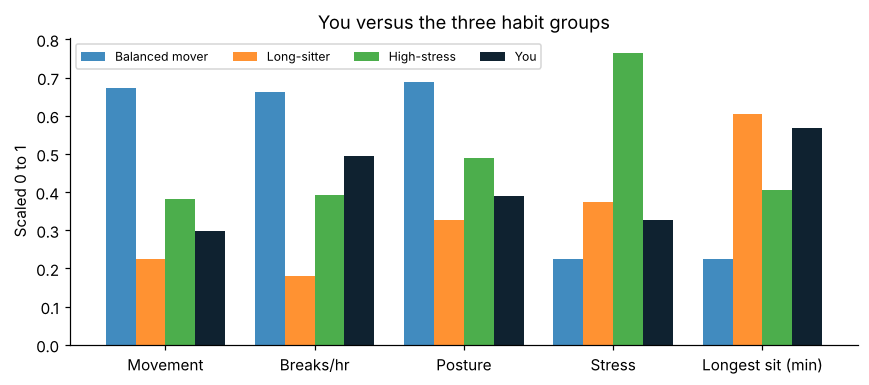

In [14]:
# Your profile against the cohort groups, on one chart
axes = ["avg_activity", "breaks_per_hr", "avg_posture", "avg_stress", "max_sit_min"]
lab = ["Movement", "Breaks/hr", "Posture", "Stress", "Longest sit (min)"]
mm = cohort[axes]; lo, hi = mm.min(), mm.max()
norm = lambda s: ((s - lo) / (hi - lo)).clip(0, 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.2; x = np.arange(len(axes))
for i, g in enumerate(["Balanced mover", "Long-sitter", "High-stress"]):
    ax.bar(x + (i-1.5)*w, norm(cohort[cohort["group"] == g][axes].mean()), w, label=g, alpha=.85)
ax.bar(x + 1.5*w, norm(pd.Series({a: me[a] for a in axes})), w, color=INK, label="You")
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylabel("Scaled 0 to 1"); ax.legend(fontsize=8, ncol=4)
ax.set_title("You versus the three habit groups"); plt.tight_layout(); plt.show()

## 6. Export for the website

The website's "You vs cohort" radar uses five axes (sitting control, breaks, movement, consistency, calm), each scaled 0 to 100 with the same formulas the website uses. This cell computes the **cohort averages** on those scales and saves them, so the website's simulated numbers can come from this analysis instead of being typed in by hand.

In [15]:
sit_ctrl = (100 - (cohort["max_sit_min"] - 40).clip(lower=0) * 3).clip(0, 100)
breaks_s = (cohort["breaks_per_hr"] * 25).clip(0, 100)             # same formula as the website: breaks x 25
move_s   = (cohort["avg_activity"] * 20).clip(0, 100)
calm_s   = (100 - cohort["avg_stress"]).clip(0, 100)
consist  = (100 - cohort["avg_anomaly"]).clip(0, 100)               # same as the website: 100 minus anomaly score

radar = [round(float(v), 0) for v in [sit_ctrl.mean(), breaks_s.mean(), move_s.mean(), consist.mean(), calm_s.mean()]]
print("Cohort averages for the radar [Sitting control, Breaks, Movement, Consistency, Calm]:", radar)

cohort.round(2).to_csv("omniband_cohort_simulated.csv", index=False)
json.dump({"note": "Simulated cohort, 300 students, seed 42. Not real student data.",
           "radar_labels": ["Sitting control", "Breaks", "Movement", "Consistency", "Calm"],
           "radar_cohort_average": radar,
           "group_sizes": cohort["group"].value_counts().to_dict(),
           "silhouette_k3": round(float(silhouette_score(X, km.labels_)), 3)},
          open("cohort_summary.json", "w"), indent=2)
print("Saved omniband_cohort_simulated.csv and cohort_summary.json")

Cohort averages for the radar [Sitting control, Breaks, Movement, Consistency, Calm]: [58.0, 22.0, 47.0, 78.0, 62.0]
Saved omniband_cohort_simulated.csv and cohort_summary.json


**To use these on the website:** open `app.js`, find the line with `Cohort average (simulated)` and replace `data: [75, 70, 65, 80, 72]` with the `radar` list printed above.

## 7. Summary, limitations and next steps

**What was built:** a labelled simulated cohort, K-Means grouping (k = 3, checked with silhouette and PCA), an Isolation Forest anomaly detector measured against injected events, a ThingSpeak loader, cluster assignment with percentile comparison, and rule-based recommendations.

**Limitations (say these in the viva)**

- The cohort is **simulated**. Results show the pipeline works, not how real students behave.
- Stress, posture, anomaly score and skin temperature are **experimental estimates** from a wrist-worn PPG sensor, a motion sensor and an NTC thermistor. They are not clinically validated.
- The recommendations are **rule-based**, driven by thresholds. The ML decides *which group* you are closest to and how you compare, not the advice text itself.
- Clustering finds groups but gives no cause-and-effect.

**Next steps after this semester:** collect real consented data from volunteer students, build a personal baseline per user, add motion-artefact filtering, validate heart rate and SpO₂ against a medical-grade device, and try supervised models once labelled data exists.